<a href="https://colab.research.google.com/github/eyadalqubaisi/clinvar-missense-data-pipeline/blob/main/clinvar_missense_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1 - Download the ClinVar variant summary table
# ClinVar is NCBI's public archive of human variants and their clinical interpretations.
!wget -q -O variant_summary.txt.gz https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz
!ls -lh variant_summary.txt.gz

-rw-r--r-- 1 root root 438M Nov  9 13:09 variant_summary.txt.gz


In [ ]:
# Step 2 - Inspect the file structure before loading it fully
import pandas as pd

preview = pd.read_csv('variant_summary.txt.gz', sep='\t', nrows=5000, low_memory=False)
print('Number of columns:', len(preview.columns))
print(list(preview.columns))

Number of columns: 43
['#AlleleID', 'Type', 'Name', 'GeneID', 'GeneSymbol', 'HGNC_ID', 'ClinicalSignificance', 'ClinSigSimple', 'LastEvaluated', 'RS# (dbSNP)', 'nsv/esv (dbVar)', 'RCVaccession', 'PhenotypeIDS', 'PhenotypeList', 'Origin', 'OriginSimple', 'Assembly', 'ChromosomeAccession', 'Chromosome', 'Start', 'Stop', 'ReferenceAllele', 'AlternateAllele', 'Cytogenetic', 'ReviewStatus', 'NumberSubmitters', 'Guidelines', 'TestedInGTR', 'OtherIDs', 'SubmitterCategories', 'VariationID', 'PositionVCF', 'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'SomaticClinicalImpact', 'SomaticClinicalImpactLastEvaluated', 'ReviewStatusClinicalImpact', 'Oncogenicity', 'OncogenicityLastEvaluated', 'ReviewStatusOncogenicity', 'SCVsForAggregateGermlineClassification', 'SCVsForAggregateSomaticClinicalImpact', 'SCVsForAggregateOncogenicityClassification']


In [ ]:
# Step 3 - Load only the columns we need, then drop the duplicate genome assembly
import pandas as pd
import numpy as np

cols = ['Type','Name','GeneSymbol','ClinicalSignificance','ReviewStatus','Assembly','Chromosome','PositionVCF','ReferenceAlleleVCF','AlternateAlleleVCF']
df = pd.read_csv('variant_summary.txt.gz', sep='\t', usecols=cols, low_memory=False)
print('Rows in raw file:', len(df))
print(df['Assembly'].value_counts(dropna=False))
df = df[df['Assembly'] == 'GRCh38'].copy()
print('Rows after keeping GRCh38 only:', len(df))

Rows in raw file: 9354555
Assembly
GRCh37    4696595
GRCh38    4643623
na           9566
NCBI36       4771
Name: count, dtype: int64
Rows after keeping GRCh38 only: 4643623


In [ ]:
# Step 4 - Keep single nucleotide variants and parse the protein change from the HGVS name
df = df[df['Type'] == 'single nucleotide variant'].copy()
print('Rows after keeping SNVs only:', len(df))

prot = df['Name'].str.extract(r'\(p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2}|Ter|=)\)')
df['aa_ref'] = prot[0]
df['aa_pos'] = pd.to_numeric(prot[1], errors='coerce')
df['aa_alt'] = prot[2]
print('Rows with a protein change parsed:', df['aa_ref'].notna().sum())
print(df[['Name','aa_ref','aa_pos','aa_alt']].head(3))

Rows after keeping SNVs only: 4292033
Rows with a protein change parsed: 3468710
                                           Name aa_ref  aa_pos aa_alt
5  NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg)    Gly  1046.0    Arg
7   NM_017547.4(FOXRED1):c.694C>T (p.Gln232Ter)    Gln   232.0    Ter
9  NM_017547.4(FOXRED1):c.1289A>G (p.Asn430Ser)    Asn   430.0    Ser


In [ ]:
# Step 5 - A missense variant swaps one amino acid for a DIFFERENT one
df = df[df['aa_ref'].notna() & df['aa_alt'].notna()].copy()
df = df[~df['aa_alt'].isin(['Ter','='])].copy()
df = df[df['aa_ref'] != df['aa_alt']].copy()
print('Rows after the missense filter:', len(df))

# Step 6 - Turn the clinical significance text into a binary label
sig = df['ClinicalSignificance'].str.strip().str.lower()
print(sig.value_counts().head(12))
pathogenic = ['pathogenic','likely pathogenic','pathogenic/likely pathogenic']
benign = ['benign','likely benign','benign/likely benign']
df['label'] = np.nan
df.loc[sig.isin(pathogenic), 'label'] = 1
df.loc[sig.isin(benign), 'label'] = 0
print('Labelled rows:', int(df['label'].notna().sum()))

Rows after the missense filter: 2575252
ClinicalSignificance
uncertain significance                          2172003
conflicting classifications of pathogenicity     122526
likely benign                                    103197
-                                                 56021
likely pathogenic                                 36060
benign                                            27105
pathogenic                                        23035
benign/likely benign                              16550
pathogenic/likely pathogenic                      13435
not provided                                       3067
other                                               479
drug response                                       376
Name: count, dtype: int64
Labelled rows: 219382


In [ ]:
# Step 7 - Keep the label, drop weak review statuses, and remove duplicate variants
df = df[df['label'].notna()].copy()
df['label'] = df['label'].astype(int)
print(df['ReviewStatus'].value_counts())
weak = ['no assertion criteria provided','no classification provided','no classifications from unflagged records','no assertion provided','no interpretation for the single variant']
df = df[~df['ReviewStatus'].str.strip().str.lower().isin(weak)].copy()
print('Rows after the review-status filter:', len(df))

df['variant_id'] = df['Chromosome'].astype(str) + '-' + df['PositionVCF'].astype(str) + '-' + df['ReferenceAlleleVCF'].astype(str) + '-' + df['AlternateAlleleVCF'].astype(str)
print('Duplicate variant ids:', int(df['variant_id'].duplicated().sum()))
df = df.drop_duplicates(subset='variant_id').copy()
print('FINAL clean dataset rows:', len(df))
print(df['label'].value_counts())

ReviewStatus
criteria provided, single submitter                     135681
criteria provided, multiple submitters, no conflicts     62453
no assertion criteria provided                           16153
reviewed by expert panel                                  5087
practice guideline                                           8
Name: count, dtype: int64
Rows after the review-status filter: 203229
Duplicate variant ids: 0
FINAL clean dataset rows: 203229
label
0    141110
1     62119
Name: count, dtype: int64


Saved clinvar_missense_clean.csv with 203229 rows and 9 columns
Unique genes: 15733
Pathogenic share: 30.6%


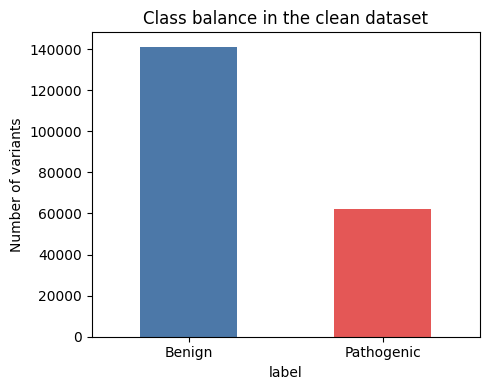

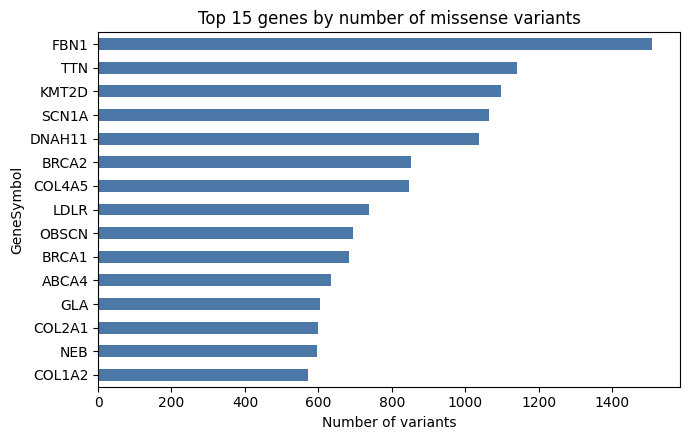

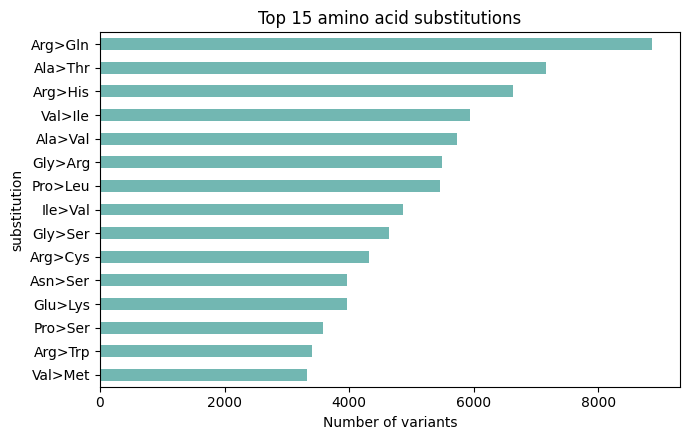

In [ ]:
# Step 8 - Save the clean dataset, then explore it with charts
import matplotlib.pyplot as plt

out = df[['variant_id','GeneSymbol','aa_ref','aa_pos','aa_alt','ClinicalSignificance','ReviewStatus','label']].copy()
out['substitution'] = out['aa_ref'] + '>' + out['aa_alt']
out.to_csv('clinvar_missense_clean.csv', index=False)
print('Saved clinvar_missense_clean.csv with', len(out), 'rows and', out.shape[1], 'columns')
print('Unique genes:', out['GeneSymbol'].nunique())
print('Pathogenic share: %.1f%%' % (100 * out['label'].mean()))

plt.figure(figsize=(5,4))
out['label'].value_counts().sort_index().plot(kind='bar', color=['#4C78A8','#E45756'])
plt.xticks([0,1], ['Benign','Pathogenic'], rotation=0)
plt.title('Class balance in the clean dataset')
plt.ylabel('Number of variants')
plt.tight_layout()
plt.savefig('fig_class_balance.png', dpi=150)
plt.show()

plt.figure(figsize=(7,4.5))
out['GeneSymbol'].value_counts().head(15).sort_values().plot(kind='barh', color='#4C78A8')
plt.title('Top 15 genes by number of missense variants')
plt.xlabel('Number of variants')
plt.tight_layout()
plt.savefig('fig_top_genes.png', dpi=150)
plt.show()

plt.figure(figsize=(7,4.5))
out['substitution'].value_counts().head(15).sort_values().plot(kind='barh', color='#72B7B2')
plt.title('Top 15 amino acid substitutions')
plt.xlabel('Number of variants')
plt.tight_layout()
plt.savefig('fig_top_substitutions.png', dpi=150)
plt.show()